# 01 · Query router: TF-IDF + logistic regression

**Goal:** before the agent does anything, guess what *kind* of question it got, in about a millisecond and for free.

| label | example | what the graph does with it |
|---|---|---|
| `factual` | "Which GPU did CRAG use?" | normal retrieval (k=4) |
| `conceptual` | "Why does CRAG use web search?" | normal retrieval (k=4) |
| `comparison` | "How does CRAG differ from Self-RAG?" | retrieve **more** chunks (k=8): the answer spans two papers |
| `off_topic` | "How do I make pancakes?" | **skip retrieval**, answer "I don't know" immediately |

`factual` and `conceptual` take the same path for now; the label is still recorded so the benchmark can report accuracy **per question type**.

**Why not ask the LLM to classify?** It would cost ~1s and a free-tier request per question, and its answer can vary between runs. TF-IDF + logistic regression runs locally in about 1 ms, gives the same answer every time, and outputs **probabilities** we can put a threshold on (section 8).

In [1]:
import json
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_val_predict,
                                     cross_val_score, train_test_split)
from sklearn.pipeline import FeatureUnion, Pipeline

ROOT = Path("..")
sys.path.insert(0, str(ROOT))
from app.router import CorpusCoverage, choose_route  # shared with the live app

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42  # any fixed number: makes the split and CV folds repeatable
LABELS = ["factual", "conceptual", "comparison", "off_topic"]

df = pd.read_csv(ROOT / "data" / "router_queries.csv")
print(len(df), "labelled questions")
df.label.value_counts()

150 labelled questions


label
factual       45
conceptual    45
comparison    30
off_topic     30
Name: count, dtype: int64

## 1 · Hold out a test set first

Split **before** looking at any model, so the test score is an honest estimate of performance on new questions.

- `stratify=y` keeps the same class mix in both halves. Without it, a random 30-question test set could get only 3 off-topic examples, or 9.
- 20% test = 30 questions. That's small, so we also use **5-fold cross-validation** on the training part to choose settings. Each training question gets used for validation once.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    df.question, df.label, test_size=0.2, stratify=df.label, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(f"train={len(X_train)}  test={len(X_test)}")
pd.crosstab(pd.concat([y_train, y_test]),
            ["train"] * len(y_train) + ["test"] * len(y_test))

train=120  test=30


col_0,test,train
label,,
comparison,6,24
conceptual,9,36
factual,9,36
off_topic,6,24


## 2 · Trap: removing stop words deletes the signal

Text-classification tutorials almost always remove stop words. scikit-learn's English list contains **how, why, what, which, both, between**, and those words are exactly what separates a factual question from a conceptual one or a comparison.

Metric: **macro-F1**, the F1 score averaged over the 4 classes with equal weight, so the smaller classes count as much as the big ones (more on that in section 7).

In [3]:
def tfidf(**args):
    # sublinear_tf: 1+log(count) instead of count, so a repeated word doesn't dominate
    return TfidfVectorizer(sublinear_tf=True, **args)

def logreg():
    # class_weight="balanced": stops the larger classes (45 vs 30) dominating
    return LogisticRegression(max_iter=2000, class_weight="balanced")

for name, args in [("keep stop words", {}), ("remove stop words", {"stop_words": "english"})]:
    pipe = Pipeline([("tfidf", tfidf(**args)), ("clf", logreg())])
    s = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1_macro")
    print(f"{name:18} macro-F1 = {s.mean():.3f} ± {s.std():.3f}")

keep stop words    macro-F1 = 0.704 ± 0.064


remove stop words  macro-F1 = 0.626 ± 0.058


## 3 · Baseline: TF-IDF only, tuned

- **`ngram_range`**: `(1,1)` uses single words only. `(1,2)` adds word pairs like *"how does"*, *"differ from"*, which carry the question's intent.
- **`C`**: the inverse of regularization strength. Small C means a simpler model that is less likely to memorize 120 examples; large C fits the training data more tightly. Cross-validation picks it.

In [4]:
grid = {"clf__C": [0.3, 1, 3, 10, 30]}
base = GridSearchCV(Pipeline([("tfidf", tfidf()), ("clf", logreg())]),
                    {**grid, "tfidf__ngram_range": [(1, 1), (1, 2)]},
                    cv=cv, scoring="f1_macro").fit(X_train, y_train)
print("best:", base.best_params_, f" CV macro-F1 = {base.best_score_:.3f}")

best: {'clf__C': 0.3, 'tfidf__ngram_range': (1, 2)}  CV macro-F1 = 0.710


## 4 · Trap: TF-IDF can't see words it has never seen

At prediction time, the vectorizer keeps **only** words that were in its training vocabulary. Look at what's left of off-topic questions:

In [5]:
vec = base.best_estimator_.named_steps["tfidf"]
for q in ["Who won the 2022 FIFA World Cup?", "How do I make pancakes?",
          "What is the best laptop for gaming?"]:
    kept = [t for t in vec.build_analyzer()(q) if t in vec.vocabulary_]
    print(f"{q!r:42} -> model sees only: {kept}")

'Who won the 2022 FIFA World Cup?'         -> model sees only: ['who', 'won', 'the', 'world', 'cup', 'who won', 'won the', 'world cup']
'How do I make pancakes?'                  -> model sees only: ['how', 'do', 'make', 'how do']
'What is the best laptop for gaming?'      -> model sees only: ['what', 'is', 'the', 'best', 'for', 'what is', 'is the', 'the best']


What makes these questions off-topic (*FIFA, pancakes, laptop, gaming*) is invisible to the model. All it has left is *"who"*, *"what is"*, *"how do"*, which also appear in on-topic questions. **No amount of tuning fixes a missing feature.**

**The fix: add one feature TF-IDF can't express.** *What fraction of the question's content words appear anywhere in the six papers?* (`CorpusCoverage` in `app/router.py`.) On-topic questions reuse the papers' vocabulary; off-topic ones mostly don't.

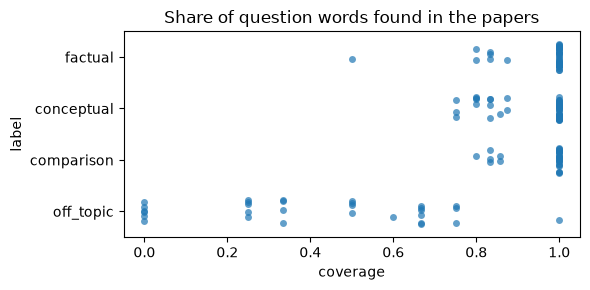

,question,coverage
120,What is the capital of France?,1.00
121,Who won the last cricket world cup?,0.75
126,What is the best phone to buy this year?,0.75


In [6]:
cov = CorpusCoverage().fit(X_train)
df["coverage"] = cov.transform(df.question)[:, 0]
fig, ax = plt.subplots(figsize=(6, 3))
sns.stripplot(data=df, x="coverage", y="label", order=LABELS, jitter=0.25, alpha=.7, ax=ax)
ax.set_title("Share of question words found in the papers"); plt.tight_layout(); plt.show()
df[df.label == "off_topic"].nlargest(3, "coverage")[["question", "coverage"]]

It separates well, but not perfectly. *"What is the capital of France?"* scores 1.0, because the Adaptive-RAG paper literally uses *"Paris is the capital of what?"* as an example. So coverage goes in as one more **feature** next to TF-IDF, rather than being used as a hard rule, and logistic regression learns how much weight it deserves.

`FeatureUnion` places the two side by side: [thousands of TF-IDF columns | 1 coverage column].

In [7]:
combined = GridSearchCV(
    Pipeline([("features", FeatureUnion([("tfidf", tfidf()), ("coverage", CorpusCoverage())])),
              ("clf", logreg())]),
    {**grid, "features__tfidf__ngram_range": [(1, 1), (1, 2)]},
    cv=cv, scoring="f1_macro").fit(X_train, y_train)
print("best:", combined.best_params_, f" CV macro-F1 = {combined.best_score_:.3f}")
print(f"(TF-IDF only was {base.best_score_:.3f})")
model = combined.best_estimator_

best: {'clf__C': 1, 'features__tfidf__ngram_range': (1, 1)}  CV macro-F1 = 0.878
(TF-IDF only was 0.710)


## 5 · Evaluate once on the held-out test set

In [8]:
for name, m in [("TF-IDF only", base.best_estimator_), ("TF-IDF + coverage", model)]:
    p = m.predict(X_test)
    print(f"{name:18} accuracy = {accuracy_score(y_test, p):.3f}   "
          f"macro-F1 = {f1_score(y_test, p, average='macro'):.3f}")
pred = model.predict(X_test)
print()
print(classification_report(y_test, pred, labels=LABELS, zero_division=0))

TF-IDF only        accuracy = 0.733   macro-F1 = 0.721
TF-IDF + coverage  accuracy = 0.867   macro-F1 = 0.870

              precision    recall  f1-score   support

     factual       0.88      0.78      0.82         9
  conceptual       0.89      0.89      0.89         9
  comparison       1.00      0.83      0.91         6
   off_topic       0.75      1.00      0.86         6

    accuracy                           0.87        30
   macro avg       0.88      0.88      0.87        30
weighted avg       0.88      0.87      0.87        30



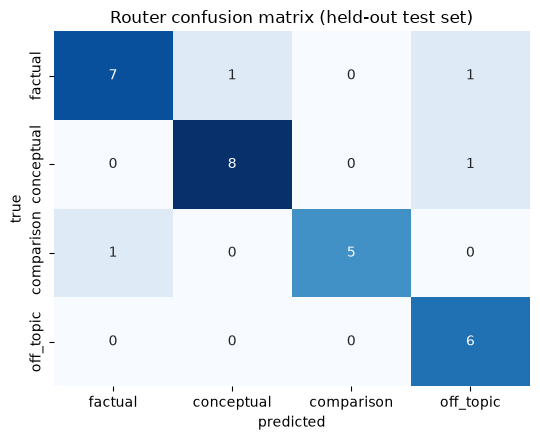

In [9]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(confusion_matrix(y_test, pred, labels=LABELS), annot=True, fmt="d",
            cmap="Blues", cbar=False, xticklabels=LABELS, yticklabels=LABELS, ax=ax)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title("Router confusion matrix (held-out test set)")
plt.tight_layout(); plt.show()

## 6 · How to read the confusion matrix

Rows are the true label, columns the prediction. The diagonal shows correct predictions; every off-diagonal cell is a specific kind of mistake. They don't all cost the same:

- `factual` ↔ `conceptual` ↔ `comparison` mix-ups: **cheap**. At worst, a few extra chunks get retrieved and graded.
- on-topic → `off_topic` (the last column): **expensive**. An answerable question gets refused.

## 7 · Trap: accuracy can lie

A model that always predicts the biggest class looks respectable on accuracy and is useless:

In [10]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
dpred = dummy.predict(X_test)
print(f"always '{dpred[0]}':  accuracy = {accuracy_score(y_test, dpred):.3f}   "
      f"macro-F1 = {f1_score(y_test, dpred, average='macro'):.3f}   "
      f"off_topic recall = {(dpred[y_test == 'off_topic'] == 'off_topic').mean():.0%}")

always 'conceptual':  accuracy = 0.300   macro-F1 = 0.115   off_topic recall = 0%


With a realistic 5% off-topic rate, "never off-topic" would score **95% accuracy** while catching **0%** of off-topic questions. That's why we report macro-F1 and per-class precision and recall, not only accuracy.

## 8 · Pick the refusal threshold from the costs

We refuse only when `off_topic` wins with probability ≥ a threshold; otherwise we fall back to the best on-topic label (`choose_route` in `app/router.py`). The threshold is chosen on **cross-validated** training predictions, so the test set isn't used to tune it.

Rule: the lowest threshold that refuses **zero** on-topic questions, but **never below 0.4**. With 4 classes, random guessing gives each class 0.25, so below 0.4 "off_topic" is barely ahead of the others. Zero errors on 96 on-topic questions doesn't prove the real error rate is zero, so we keep a margin.

In [11]:
def threshold_table(m):
    proba = cross_val_predict(m, X_train, y_train, cv=cv, method="predict_proba")
    classes = list(m.classes_)
    p_off = proba[:, classes.index("off_topic")]
    top_off = proba.argmax(1) == classes.index("off_topic")
    is_off = (y_train == "off_topic").to_numpy()
    rows = []
    for t in [0.0, 0.3, 0.4, 0.5, 0.6, 0.7]:
        refused = top_off & (p_off >= t)
        rows.append({"threshold": t,
                     "on-topic wrongly refused": int((refused & ~is_off).sum()),
                     "off-topic caught": int((refused & is_off).sum())})
    return pd.DataFrame(rows)

t_base, t_comb = threshold_table(base.best_estimator_), threshold_table(model)
print(f"off-topic questions in training set: {(y_train == 'off_topic').sum()}")
t_base.merge(t_comb, on="threshold", suffixes=(" [tfidf]", " [+coverage]"))

off-topic questions in training set: 24


,threshold,on-topic wrongly refused [tfidf],off-topic caught [tfidf],on-topic wrongly refused [+coverage],off-topic caught [+coverage]
0,0.0,8,15,0,22
1,0.3,4,5,0,22
2,0.4,0,0,0,18
3,0.5,0,0,0,14
4,0.6,0,0,0,13
5,0.7,0,0,0,9


In [12]:
safe = t_comb[(t_comb.threshold >= 0.4) & (t_comb["on-topic wrongly refused"] == 0)].iloc[0]
OFF_TOPIC_MIN_PROB = float(safe.threshold)
print(f"chosen threshold {OFF_TOPIC_MIN_PROB}: catches {int(safe['off-topic caught'])}/"
      f"{(y_train == 'off_topic').sum()} off-topic, refuses 0 on-topic (cross-validated)")

chosen threshold 0.4: catches 18/24 off-topic, refuses 0 on-topic (cross-validated)


## 9 · Out-of-sample check: the 30 benchmark questions

These were written separately as the benchmark test set and **never used in training**, so this is an independent test. `q30` ("What accuracy does CRAG report on MMLU?") *sounds* on-topic, but the answer isn't in the papers. The router can't know that; the grader will catch it. **Two layers:** the router stops obvious off-topic questions cheaply, and the grader catches the subtle ones.

In [13]:
bench = pd.DataFrame(json.loads((ROOT / "data" / "testset.json").read_text(encoding="utf-8")))
bench["type"] = bench["type"].replace({"out_of_scope": "off_topic"})
probas = model.predict_proba(bench.question)
bench["predicted"] = [choose_route(p, list(model.classes_), OFF_TOPIC_MIN_PROB) for p in probas]
print(f"accuracy on benchmark questions: {(bench.predicted == bench.type).mean():.0%}")
wrongly_refused = bench[(bench.predicted == "off_topic") & (bench.type != "off_topic")]
print(f"on-topic questions wrongly refused: {len(wrongly_refused)}")
bench.loc[bench.predicted != bench.type, ["id", "question", "type", "predicted"]]

accuracy on benchmark questions: 60%
on-topic questions wrongly refused: 0


,id,question,type,predicted
5,q06,What model is CRAG's retrieval evaluator based...,factual,comparison
8,q09,Which single-hop and which multi-hop QA datase...,factual,comparison
11,q12,By how much does ReAct improve success rates o...,factual,comparison
16,q17,What are the four types of reflection tokens i...,conceptual,factual
19,q20,What is the difference between RAG-Sequence an...,conceptual,comparison
20,q21,"What do the labels A, B and C mean in Adaptive...",conceptual,comparison
22,q23,What is the U-shaped performance curve describ...,conceptual,factual
23,q24,"In ReAct combined with CoT-SC, when does the s...",conceptual,factual
25,q26,Adaptive-RAG and Self-RAG both decide whether ...,comparison,conceptual
26,q27,How does the way ReAct retrieves information d...,comparison,conceptual


**Reading these misses honestly:**
- **Off-topic:** the FIFA question is caught, and **no answerable question is refused**. That's the result that matters.
- `q30` (MMLU) is routed as `factual`, as expected: its words are all on-topic. The grader handles it.
- Most other misses are `factual`/`conceptual` ↔ `comparison`. Some are arguably **label ambiguity in the test set** rather than router errors: *"What is the difference between RAG-Sequence and RAG-Token?"* is labelled `conceptual`, but it literally asks for a difference. Two-part factual questions (*"which single-hop **and** which multi-hop datasets"*) look like comparisons because `and` is a strong comparison signal.
- These mix-ups are **cheap**: a `comparison` route only retrieves 8 chunks instead of 4.

A real fix would need more and better-defined training labels: *the model is only as good as the label definitions.*

## 10 · What did the model learn?

Logistic regression is easy to inspect: every feature gets a weight per class. The coverage feature should push **against** `off_topic`, and the n-grams should look like question intent.

In [14]:
union, clf = model.named_steps["features"], model.named_steps["clf"]
names = np.array(union.get_feature_names_out())
weights = pd.DataFrame(clf.coef_, index=clf.classes_, columns=names)
print("coverage weight per class:")
print(weights.filter(like="coverage").round(2).T.to_string(), "\n")
pd.DataFrame({c: [n.replace("tfidf__", "") for n in weights.loc[c].nlargest(8).index]
              for c in clf.classes_})

coverage weight per class:
                    comparison  conceptual  factual  off_topic
coverage__coverage        0.93        0.92     1.34      -3.19 



,comparison,conceptual,factual,off_topic
0,compare,why,coverage__coverage,work
1,and,coverage__coverage,many,capital
2,rag,does,which,france
3,coverage__coverage,how,use,who
4,crag,its,what,photosynthesis
5,self,retrieval,for,what
6,vs,reasoning,paper,is
7,differ,trained,dataset,lora


## 11 · Retrain on all 150 and save

The test set did its job (an honest score), so the final model trains on **all** the data. The threshold and scikit-learn version are saved with it: a pickle should only be loaded with the same scikit-learn version, and pickles must never come from untrusted sources (loading one can run arbitrary code).

In [15]:
final = sklearn.base.clone(model).fit(df.question, df.label)
bundle = {"pipeline": final, "off_topic_min_prob": OFF_TOPIC_MIN_PROB,
          "sklearn_version": sklearn.__version__, "labels": LABELS}
out = ROOT / "models" / "router.pkl"
out.parent.mkdir(exist_ok=True)
joblib.dump(bundle, out)
print(f"saved {out} ({out.stat().st_size / 1024:.0f} KB), sklearn {sklearn.__version__}")

saved ..\models\router.pkl (50 KB), sklearn 1.9.1
